#  Blood Donation Dataset 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:

df = pd.read_csv('blood_donation.csv', keep_default_na=False)
print('Rows and columns:', df.shape)

Rows and columns: (10000, 18)


In [3]:
df.head()

,Donor_ID,Full_Name,Gender,Age,Blood_Group,Contact_Number,Email,City,State,Country,Last_Donation_Date,Total_Donations,Eligible_for_Donation,Medical_Condition,Weight_kg,Hemoglobin_g_dL,Donation_Center,Registration_Date
0,DNR000001,Sangeeta Menon,Female,38,O+,1819600042,sangeeta.menon8280@gmail.com,Kolkata,West Bengal,India,07-10-2025,1,Yes,None,66.6,13.6,Red Cross Blood Bank,02-07-2021
1,DNR000002,Meena Iyer,Female,49,B+,265423420,meena.iyer6225@gmail.com,Jaipur,Rajasthan,India,08-11-2020,1,No,Hypertension,70.8,14.0,Metro Blood Bank,03-03-2023
2,DNR000003,Priya Nair,Female,29,B+,1849593012,priya.nair4742@gmail.com,Gurgaon,Haryana,India,12-04-2025,2,No,Diabetes,73.4,12.5,Fortis Blood Bank,15-10-2015
3,DNR000004,Vijay Kapoor,Male,29,O+,3419283185,vijay.kapoor4423@gmail.com,Thiruvananthapuram,Kerala,India,21-02-2025,1,Yes,None,57.9,14.8,NABL Blood Centre,09-05-2022
4,DNR000005,Rahul Iyer,Male,27,A+,6413953676,rahul.iyer2341@gmail.com,Bhopal,Madhya Pradesh,India,18-04-2024,1,Yes,None,74.0,17.1,NABL Blood Centre,13-07-2022


In [4]:
df.columns.tolist()

['Donor_ID', 'Full_Name', 'Gender', 'Age', 'Blood_Group', 'Contact_Number', 'Email', 'City', 'State', 'Country', 'Last_Donation_Date', 'Total_Donations', 'Eligible_for_Donation', 'Medical_Condition', 'Weight_kg', 'Hemoglobin_g_dL', 'Donation_Center', 'Registration_Date']

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Donor_ID               10000 non-null  str    
 1   Full_Name              10000 non-null  str    
 2   Gender                 10000 non-null  str    
 3   Age                    10000 non-null  int64  
 4   Blood_Group            10000 non-null  str    
 5   Contact_Number         10000 non-null  int64  
 6   Email                  10000 non-null  str    
 7   City                   10000 non-null  str    
 8   State                  10000 non-null  str    
 9   Country                10000 non-null  str    
 10  Last_Donation_Date     10000 non-null  str    
 11  Total_Donations        10000 non-null  int64  
 12  Eligible_for_Donation  10000 non-null  str    
 13  Medical_Condition      10000 non-null  str    
 14  Weight_kg              10000 non-null  float64
 15  Hemoglobin_g_d

In [6]:
df.describe()

,Age,Contact_Number,Total_Donations,Weight_kg,Hemoglobin_g_dL
count,10000.000000,1.000000e+04,10000.000000,10000.000000,10000.00000
mean,33.897800,5.028221e+09,2.084800,68.015560,13.73798
std,9.417071,2.876037e+09,1.324003,10.014265,1.26601
min,18.000000,3.639000e+05,0.000000,45.000000,10.00000
25%,27.000000,2.538943e+09,1.000000,61.100000,12.80000
50%,34.000000,5.060247e+09,2.000000,67.900000,13.70000
75%,40.000000,7.494996e+09,3.000000,74.900000,14.60000
max,65.000000,9.998636e+09,9.000000,110.000000,18.00000


In [7]:
def check_missing(data):
    
    empty = (data.astype(str).apply(lambda col: col.str.strip() == '')).sum()
    return empty

def check_duplicates(data):
    return data.duplicated().sum()

print('Duplicate rows       :', check_duplicates(df))
print('Duplicate Donor_IDs  :', df['Donor_ID'].duplicated().sum())
print()
print('Empty cells in each column:')
check_missing(df)

Duplicate rows       : 0
Duplicate Donor_IDs  : 0

Empty cells in each column:


,0
Donor_ID,0
Full_Name,0
Gender,0
Age,0
Blood_Group,0
Contact_Number,0
Email,0
City,0
State,0
Country,0


In [8]:

df.nunique()

,0
Donor_ID,10000
Full_Name,512
Gender,3
Age,48
Blood_Group,8
Contact_Number,10000
Email,9987
City,20
State,15
Country,1


In [9]:

clean = df.copy()


def clean_text(column):
    return column.str.strip().str.replace(r'\s+', ' ', regex=True)

In [10]:
print('All IDs unique?', clean['Donor_ID'].is_unique)
clean['Donor_ID'] = clean_text(clean['Donor_ID'])
clean['Donor_ID'].head()

All IDs unique? True


,Donor_ID
0,DNR000001
1,DNR000002
2,DNR000003
3,DNR000004
4,DNR000005


In [11]:
clean['Full_Name'] = clean_text(clean['Full_Name']).str.title()
print('Different names:', clean['Full_Name'].nunique(), 'for', len(clean), 'donors')
clean['Full_Name'].head()

Different names: 512 for 10000 donors


,Full_Name
0,Sangeeta Menon
1,Meena Iyer
2,Priya Nair
3,Vijay Kapoor
4,Rahul Iyer


In [12]:
clean['Gender'] = clean_text(clean['Gender']).str.title()
clean['Gender'].value_counts()

,count
Gender,
Female,4986
Male,4906
Other,108


In [13]:
print('Youngest:', clean['Age'].min(), ' Oldest:', clean['Age'].max())
print('Ages outside 18-65:', (~clean['Age'].between(18, 65)).sum())


def make_age_group(age):
    if age <= 25:
        return '18-25'
    elif age <= 35:
        return '26-35'
    elif age <= 45:
        return '36-45'
    elif age <= 55:
        return '46-55'
    else:
        return '56-65'

clean['Age_Group'] = clean['Age'].apply(make_age_group)
clean['Age_Group'].value_counts().sort_index()

Youngest: 18  Oldest: 65
Ages outside 18-65: 0


,count
Age_Group,
18-25,2079
26-35,3645
36-45,3123
46-55,1031
56-65,122


All ages are between 18 and 65, so nothing to fix. We added a new column `Age_Group`.

In [14]:
clean['Blood_Group'] = clean_text(clean['Blood_Group']).str.upper()
valid_groups = ['A+', 'A-', 'B+', 'B-', 'AB+', 'AB-', 'O+', 'O-']
print('Wrong blood groups:', (~clean['Blood_Group'].isin(valid_groups)).sum())
clean['Blood_Group'].value_counts()

Wrong blood groups: 0


,count
Blood_Group,
O+,3729
B+,3136
A+,1842
O-,419
AB+,371
A-,208
B-,194
AB-,101


In [15]:

clean['Contact_Number'] = clean['Contact_Number'].astype(str).str.strip()


def is_valid_phone(number):
    return len(number) == 10 and number[0] in '6789'

clean['Phone_Valid'] = clean['Contact_Number'].apply(is_valid_phone)
print('Valid phone numbers  :', clean['Phone_Valid'].sum())
print('Invalid phone numbers:', (~clean['Phone_Valid']).sum())
print(f"Percentage valid: {clean['Phone_Valid'].mean() * 100:.1f}%")

Valid phone numbers  : 4044
Invalid phone numbers: 5956
Percentage valid: 40.4%


Most phone numbers are not valid mobile numbers. We do **not** delete them (we cannot know the real number), we just mark them in `Phone_Valid`.

In [16]:
clean['Email'] = clean['Email'].str.strip().str.lower()
print('Emails without @ :', (~clean['Email'].str.contains('@')).sum())
print('Rows with a repeated email:', clean['Email'].duplicated(keep=False).sum())
print(clean['Email'].str.split('@').str[1].value_counts())

Emails without @ : 0
Rows with a repeated email: 26
Email
gmail.com    10000
Name: count, dtype: int64


In [17]:
clean['City'] = clean_text(clean['City']).str.title()
clean['State'] = clean_text(clean['State']).str.title()
clean['Country'] = clean_text(clean['Country']).str.title()

print('Cities :', clean['City'].nunique())
print('States :', clean['State'].nunique())
print('Countries:', clean['Country'].unique())

Cities : 20
States : 15
Countries: <StringArray>
['India']
Length: 1, dtype: str


`Country` is always India, so we will drop it at the end.

In [18]:

def to_date(column):
    column = column.str.strip()
    column = column.replace('Never', np.nan)
    return pd.to_datetime(column, format='%d-%m-%Y')

clean['Ever_Donated'] = clean['Last_Donation_Date'].str.strip() != 'Never'
clean['Last_Donation_Date'] = to_date(clean['Last_Donation_Date'])
clean['Registration_Date'] = to_date(clean['Registration_Date'])

print('Last donation :', clean['Last_Donation_Date'].min().date(), 'to', clean['Last_Donation_Date'].max().date())
print('Registration  :', clean['Registration_Date'].min().date(), 'to', clean['Registration_Date'].max().date())

Last donation : 2020-11-08 to 2025-11-07
Registration  : 2008-02-29 to 2025-11-06


In [19]:

today = clean['Last_Donation_Date'].max()          
clean['Days_Since_Last_Donation'] = (today - clean['Last_Donation_Date']).dt.days
clean['Registration_Year'] = clean['Registration_Date'].dt.year

print('Our "today" is:', today.date())
print()

print(pd.crosstab(clean['Total_Donations'] == 0, clean['Ever_Donated'],
                  rownames=['Total_Donations is 0'], colnames=['Ever donated']))


before = clean['Last_Donation_Date'] < clean['Registration_Date']
print('\nDonors whose last donation is BEFORE registration:', before.sum())

Our "today" is: 2025-11-07

Ever donated          False  True 
Total_Donations is 0              
False                     0   9424
True                    576      0

Donors whose last donation is BEFORE registration: 358


In [20]:
clean['Eligible_for_Donation'] = clean_text(clean['Eligible_for_Donation']).str.title()

# a 0/1 column makes calculations easy (1 = eligible)
clean['Eligible_Num'] = clean['Eligible_for_Donation'].map({'Yes': 1, 'No': 0})
clean['Eligible_for_Donation'].value_counts()

,count
Eligible_for_Donation,
Yes,6416
No,3584


In [21]:
clean['Donation_Center'] = clean_text(clean['Donation_Center'])
clean['Donation_Center'].value_counts()

,count
Donation_Center,
Corporate Health Centre,1039
Red Cross Blood Bank,1033
NABL Blood Centre,1032
Private Diagnostic Centre,1030
City Blood Centre,1003
Metro Blood Bank,1000
Apollo Hospitals Blood Bank,973
Fortis Blood Bank,971
Government Blood Bank,968


In [22]:

print(clean['Medical_Condition'].value_counts())
print()
print(clean[['Weight_kg', 'Hemoglobin_g_dL']].describe())

Medical_Condition
None                    7805
Hypertension             614
Anemia                   469
Diabetes                 388
Asthma                   308
Recent Surgery           207
Infection (resolved)     109
Cardiac issues           100
Name: count, dtype: int64

          Weight_kg  Hemoglobin_g_dL
count  10000.000000      10000.00000
mean      68.015560         13.73798
std       10.014265          1.26601
min       45.000000         10.00000
25%       61.100000         12.80000
50%       67.900000         13.70000
75%       74.900000         14.60000
max      110.000000         18.00000


The values are realistic (weight 45–110 kg, haemoglobin 10–18 g/dL) and there are very few outliers, so these three columns are left exactly as they are.

In [24]:
clean = clean.drop(columns=['Country'])      
clean.to_csv('blood_donation_clean_simple.csv', index=False)

print('Before cleaning:', df.shape)
print('After cleaning :', clean.shape)
print()
print('Empty values left (only the date of donors who never donated):')
print(clean.isna().sum()[clean.isna().sum() > 0])

Before cleaning: (10000, 18)
After cleaning : (10000, 23)

Empty values left (only the date of donors who never donated):
Last_Donation_Date          576
Days_Since_Last_Donation    576
dtype: int64


In [25]:

df = clean.copy()


def plot_counts(column, title=None):
    order = df[column].value_counts().index
    sns.countplot(data=df, y=column, order=order)
    plt.title(title or column)
    plt.show()

def plot_hist(column, bins=30):
    sns.histplot(df[column], bins=bins, kde=True)
    plt.axvline(df[column].mean(), color='red', linestyle='--', label='mean')
    plt.title('Distribution of ' + column)
    plt.legend()
    plt.show()

In [27]:
df[['Age', 'Weight_kg', 'Hemoglobin_g_dL', 'Total_Donations']].describe().round(2)

,Age,Weight_kg,Hemoglobin_g_dL,Total_Donations
count,10000.00,10000.00,10000.00,10000.00
mean,33.90,68.02,13.74,2.08
std,9.42,10.01,1.27,1.32
min,18.00,45.00,10.00,0.00
25%,27.00,61.10,12.80,1.00
50%,34.00,67.90,13.70,2.00
75%,40.00,74.90,14.60,3.00
max,65.00,110.00,18.00,9.00


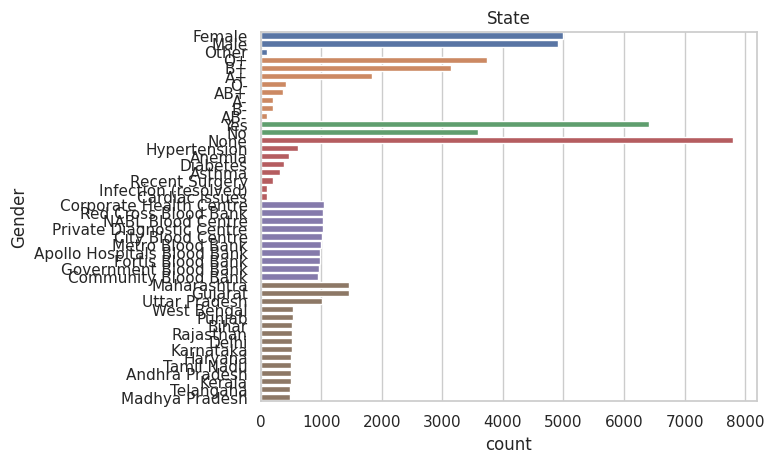

In [28]:
plot_counts('Gender')
plot_counts('Blood_Group')
plot_counts('Eligible_for_Donation')
plot_counts('Medical_Condition')
plot_counts('Donation_Center')
plot_counts('State')

In [29]:

def show_percent(column):
    return (df[column].value_counts(normalize=True) * 100).round(1)

show_percent('Blood_Group')

,proportion
Blood_Group,
O+,37.3
B+,31.4
A+,18.4
O-,4.2
AB+,3.7
A-,2.1
B-,1.9
AB-,1.0


In [30]:
show_percent('Medical_Condition')

,proportion
Medical_Condition,
None,78.0
Hypertension,6.1
Anemia,4.7
Diabetes,3.9
Asthma,3.1
Recent Surgery,2.1
Infection (resolved),1.1
Cardiac issues,1.0


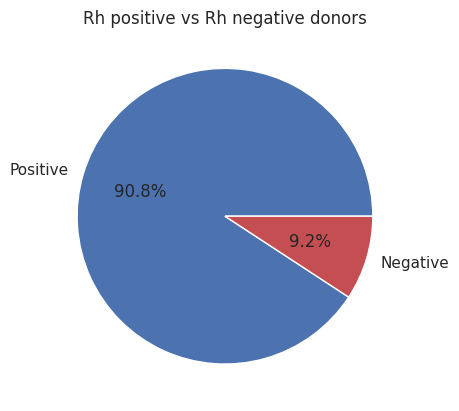

In [31]:

rh = df['Blood_Group'].apply(lambda x: 'Positive' if x.endswith('+') else 'Negative')
rh.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#4c72b0', '#c44e52'])
plt.ylabel('')
plt.title('Rh positive vs Rh negative donors')
plt.show()

Only about 9% of donors are Rh-negative, so negative blood groups are scarce.

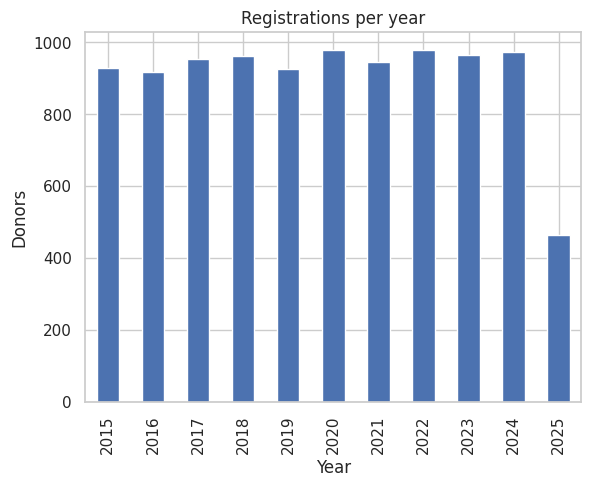

In [32]:

year_counts = df['Registration_Year'].value_counts().sort_index()
year_counts = year_counts[year_counts.index >= 2015]
year_counts.plot(kind='bar')
plt.title('Registrations per year')
plt.xlabel('Year')
plt.ylabel('Donors')
plt.show()

Donated in last 90 days : 19.9%
Donated in last 1 year  : 52.5%
Donated over 2 years ago: 24.6%


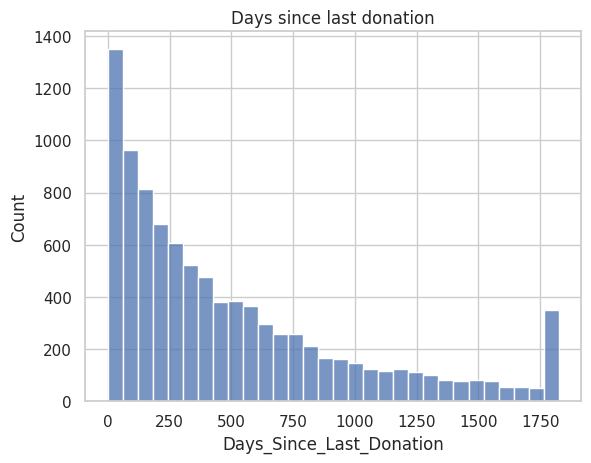

In [33]:
sns.histplot(df['Days_Since_Last_Donation'].dropna(), bins=30)
plt.title('Days since last donation')
plt.show()

days = df['Days_Since_Last_Donation'].dropna()
print(f'Donated in last 90 days : {(days <= 90).mean() * 100:.1f}%')
print(f'Donated in last 1 year  : {(days <= 365).mean() * 100:.1f}%')
print(f'Donated over 2 years ago: {(days > 730).mean() * 100:.1f}%')

Registrations are steady (about 900–980 per year). The last donation dates are spread evenly over 5 years, so there is no busy season. Many donors have not donated for a long time.

In [34]:
def eligible_rate(column):
    
    return (df.groupby(column)['Eligible_Num'].mean() * 100).round(1)

eligible_rate('Medical_Condition')

,Eligible_Num
Medical_Condition,
Anemia,0.0
Asthma,0.0
Cardiac issues,0.0
Diabetes,0.0
Hypertension,0.0
Infection (resolved),0.0
None,82.2
Recent Surgery,0.0


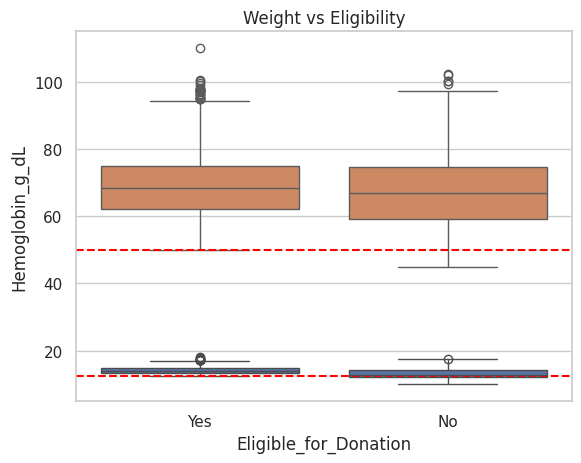

In [35]:
sns.boxplot(data=df, x='Eligible_for_Donation', y='Hemoglobin_g_dL')
plt.axhline(12.5, color='red', linestyle='--')
plt.title('Hemoglobin vs Eligibility')
plt.show()

sns.boxplot(data=df, x='Eligible_for_Donation', y='Weight_kg')
plt.axhline(50, color='red', linestyle='--')
plt.title('Weight vs Eligibility')
plt.show()

In [36]:

no_disease = df['Medical_Condition'] == 'None'
good_hb = df['Hemoglobin_g_dL'] >= 12.5
good_weight = df['Weight_kg'] >= 50

my_rule = np.where(no_disease & good_hb & good_weight, 'Yes', 'No')
print('Does my rule match the data?', (my_rule == df['Eligible_for_Donation']).mean() * 100, '%')

Does my rule match the data? 100.0 %


**Big finding:** eligibility follows a clear rule that matches **100%** of the donors.
A donor is eligible **only if**: (1) no medical condition, (2) haemoglobin ≥ 12.5 g/dL and (3) weight ≥ 50 kg.

In [37]:
# Why are donors NOT eligible?
not_eligible = df[df['Eligible_Num'] == 0]
has_disease = (not_eligible['Medical_Condition'] != 'None').sum()
low_hb = ((not_eligible['Medical_Condition'] == 'None') & (not_eligible['Hemoglobin_g_dL'] < 12.5)).sum()
low_weight = ((not_eligible['Medical_Condition'] == 'None') & (not_eligible['Hemoglobin_g_dL'] >= 12.5)).sum()

print('Not eligible donors:', len(not_eligible))
print('  because of a medical condition :', has_disease)
print('  healthy but low hemoglobin     :', low_hb)
print('  healthy, good Hb, low weight   :', low_weight)

Not eligible donors: 3584
  because of a medical condition : 2195
  healthy but low hemoglobin     : 1145
  healthy, good Hb, low weight   : 244


In [38]:

print(eligible_rate('Gender'), '\n')
print(eligible_rate('Age_Group'), '\n')
print(eligible_rate('Blood_Group'), '\n')
print(eligible_rate('Donation_Center'))

Gender
Female    53.4
Male      75.2
Other     59.3
Name: Eligible_Num, dtype: float64 

Age_Group
18-25    64.4
26-35    63.8
36-45    64.1
46-55    64.3
56-65    68.9
Name: Eligible_Num, dtype: float64 

Blood_Group
A+     63.4
A-     69.7
AB+    68.5
AB-    69.3
B+     65.1
B-     67.5
O+     62.7
O-     64.4
Name: Eligible_Num, dtype: float64 

Donation_Center
Apollo Hospitals Blood Bank    64.7
City Blood Centre              64.2
Community Blood Bank           60.0
Corporate Health Centre        63.4
Fortis Blood Bank              62.9
Government Blood Bank          66.1
Metro Blood Bank               64.4
NABL Blood Centre              64.1
Private Diagnostic Centre      66.9
Red Cross Blood Bank           64.6
Name: Eligible_Num, dtype: float64


Gender is the only column with a big difference. Age group, blood group and donation centre make almost no difference.

Gender
Female    12.98
Male      14.52
Other     13.48
Name: Hemoglobin_g_dL, dtype: float64

% of donors with Hemoglobin below 12.5:
Gender
Female    29.6
Male       2.1
Other     16.7
Name: Hemoglobin_g_dL, dtype: float64


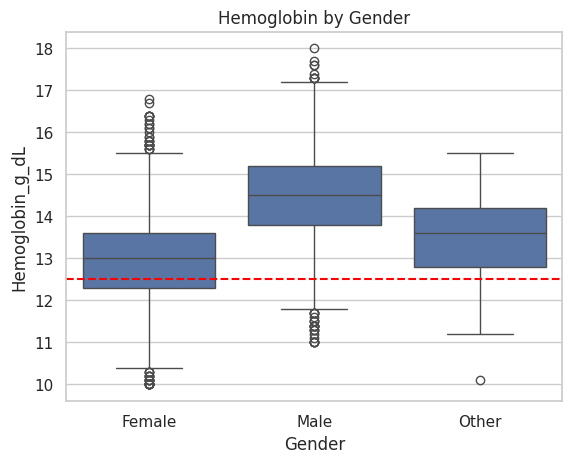

In [39]:
sns.boxplot(data=df, x='Gender', y='Hemoglobin_g_dL')
plt.axhline(12.5, color='red', linestyle='--')
plt.title('Hemoglobin by Gender')
plt.show()

print(df.groupby('Gender')['Hemoglobin_g_dL'].mean().round(2))
print()
low = df['Hemoglobin_g_dL'] < 12.5
print('% of donors with Hemoglobin below 12.5:')
print((low.groupby(df['Gender']).mean() * 100).round(1))

Women have about 1.5 g/dL lower haemoglobin than men. About **30% of women** are below the 12.5 limit compared to only **2% of men**. This is why fewer women are eligible.

In [40]:
# Hemoglobin for each medical condition
df.groupby('Medical_Condition')['Hemoglobin_g_dL'].mean().round(2).sort_values()

,Hemoglobin_g_dL
Medical_Condition,
Anemia,12.86
Diabetes,13.76
None,13.78
Hypertension,13.78
Asthma,13.80
Recent Surgery,13.81
Cardiac issues,13.84
Infection (resolved),13.84


Only **Anemia** donors have clearly lower haemoglobin. The other conditions have the same average as healthy donors.

Donated 0 or 1 time : 40.2%
Donated 3+ times    : 32.7%
Donated 5+ times    : 5.1%
Maximum donations   : 9


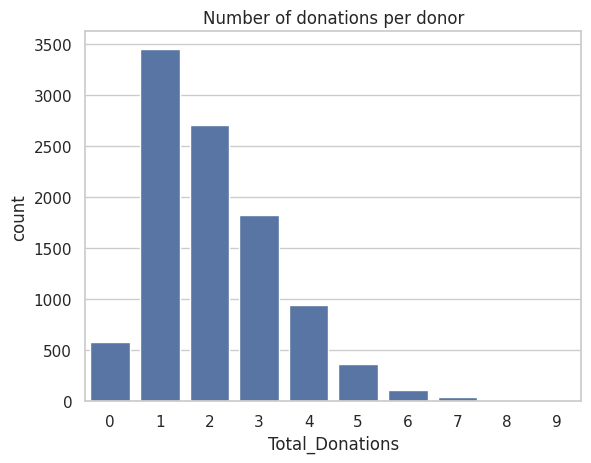

In [41]:
sns.countplot(data=df, x='Total_Donations')
plt.title('Number of donations per donor')
plt.show()

print(f"Donated 0 or 1 time : {(df['Total_Donations'] <= 1).mean() * 100:.1f}%")
print(f"Donated 3+ times    : {(df['Total_Donations'] >= 3).mean() * 100:.1f}%")
print(f"Donated 5+ times    : {(df['Total_Donations'] >= 5).mean() * 100:.1f}%")
print('Maximum donations   :', df['Total_Donations'].max())

In [42]:
# Does a donor who registered earlier donate more?
df['Years_Registered'] = (today - df['Registration_Date']).dt.days / 365
print('Correlation between years registered and donations:',
      round(df['Years_Registered'].corr(df['Total_Donations']), 3))
df.groupby('Age_Group')['Total_Donations'].mean().round(2)

Correlation between years registered and donations: 0.001


,Total_Donations
Age_Group,
18-25,2.10
26-35,2.07
36-45,2.10
46-55,2.08
56-65,1.92


A donor who registered 10 years ago has donated about the same number of times as someone who registered last month (correlation is almost 0). Real data would usually not look like this.

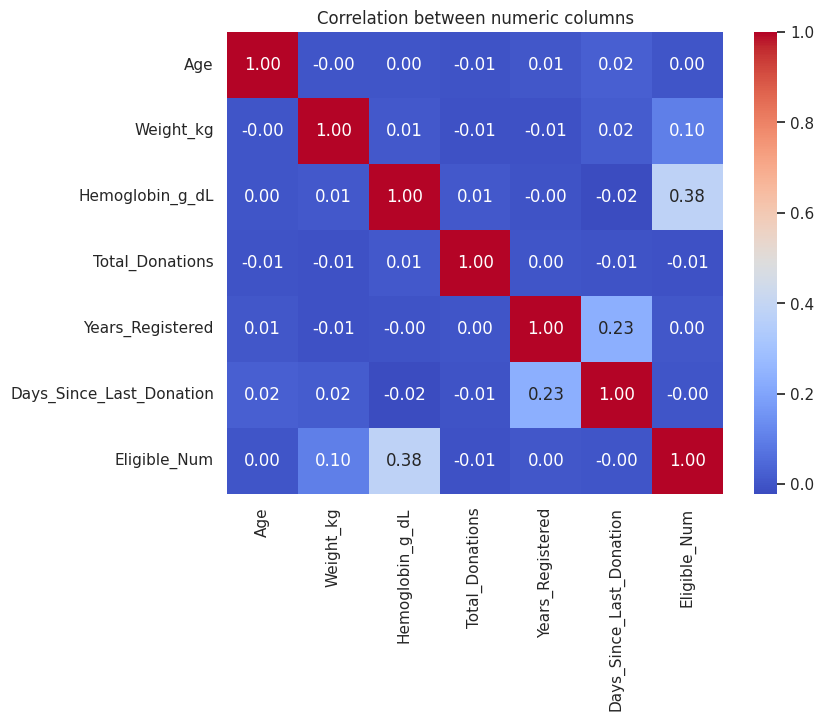

In [43]:
num_cols = ['Age', 'Weight_kg', 'Hemoglobin_g_dL', 'Total_Donations', 'Years_Registered', 'Days_Since_Last_Donation', 'Eligible_Num']
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between numeric columns')
plt.show()

Only `Eligible_Num` has a visible link with `Hemoglobin_g_dL` (positive). Almost all other pairs are close to 0.

Donor_Group
Not eligible                          3584
Eligible - donated in last year       3171
Eligible - not donated for 1+ year    2859
Eligible - never donated               386
Name: count, dtype: int64

Donor_Group
Not eligible                          35.8
Eligible - donated in last year       31.7
Eligible - not donated for 1+ year    28.6
Eligible - never donated               3.9
Name: count, dtype: float64


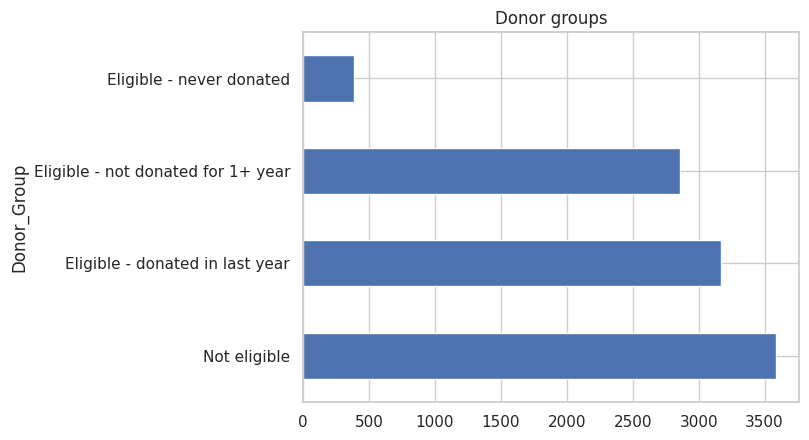

In [44]:
def donor_group(row):
    if row['Eligible_Num'] == 0:
        return 'Not eligible'
    elif not row['Ever_Donated']:
        return 'Eligible - never donated'
    elif row['Days_Since_Last_Donation'] <= 365:
        return 'Eligible - donated in last year'
    else:
        return 'Eligible - not donated for 1+ year'

df['Donor_Group'] = df.apply(donor_group, axis=1)
groups = df['Donor_Group'].value_counts()
print(groups)
print()
print((groups / len(df) * 100).round(1))

groups.plot(kind='barh')
plt.title('Donor groups')
plt.show()

About one third of all donors are eligible but have **never donated or have not donated for over a year**. They are the easiest donors to contact again.

In [45]:
problems = pd.Series({
    'Invalid phone numbers': (~df['Phone_Valid']).sum(),
    'Rows with a repeated email': df['Email'].duplicated(keep=False).sum(),
    'Last donation before registration': (df['Last_Donation_Date'] < df['Registration_Date']).sum(),
})
problems

,0
Invalid phone numbers,5956
Rows with a repeated email,26
Last donation before registration,358



## Step 6: Final insights (summary in simple words)

### About the data
1. The dataset has **10,000 donors and 18 columns**. There are no empty cells and no duplicate rows.
2. `Medical_Condition = None` and `Last_Donation_Date = Never` look like missing values, but they are real answers (no disease / never donated).
3. `Country` is always India, so it is not useful.

### Data quality problems
1. **About 60% of phone numbers (5,956) are not valid mobile numbers.**
2. **358 donors** have a last donation date before their registration date.
3. **26 rows** share an email address with another donor (13 emails used twice).
4. Weight and haemoglobin have very few outliers (27 and 28), and the values are realistic, so they were not changed.

### Who are the donors?
1. Gender is balanced: about 50% female, 49% male, 1% other.
2. Average age is about 34. Most donors are 26–45 years old.
3. **O+ (37%) and B+ (31%)** are the most common blood groups. Only about 9% are Rh-negative, and **AB- is the rarest (1%)**.
4. 78% of donors have no medical condition. The most common conditions are hypertension (6.1%), anemia (4.7%) and diabetes (3.9%).
5. Donors are spread evenly across cities and donation centres.

### What decides eligibility? (most important)
1. **64% of donors are eligible** and 36% are not.
2. A donor is eligible **only if all three are true**: no medical condition, haemoglobin ≥ 12.5 g/dL, and weight ≥ 50 kg. This rule matches **all 10,000 donors**.
3. Reasons for the 3,584 not-eligible donors: **2,195** have a medical condition, **1,145** are healthy but have low haemoglobin, and **244** are only below the weight limit.
4. Age group, blood group and donation centre make only small differences to eligibility.

### Gender and haemoglobin
1. Average haemoglobin: **women 12.98**, **men 14.52** g/dL.
2. **30% of women** are below 12.5 g/dL, but only **2% of men**.
3. So only **53% of women are eligible, compared to 75% of men**.
4. Only anemia is linked to lower haemoglobin; other conditions look the same as healthy donors.

### Donation behaviour
1. 40% of donors have donated 0 or 1 time; only 5% have donated 5 or more times (maximum 9).
2. Of the donors who donated before: 20% gave blood in the last 90 days, 52% in the last year, and 25% more than 2 years ago.
3. The number of donations does **not** depend on age, or on how long ago the donor registered. This is unusual for real data, so the data may be artificial (synthetic).

### Donor groups
| Group | Share of donors |
|---|---|
| Not eligible | 35.8% |
| Eligible – donated in the last year | 31.7% |
| Eligible – not donated for 1+ year | 28.6% |
| Eligible – never donated | 3.9% |

About **3,245 donors (32.5%)** are eligible but have not donated for over a year or have never donated.

### What can be done?
1. **Contact the ~3,245 eligible but inactive donors first** – they need no extra checks.
2. **Run haemoglobin / iron awareness programmes for women**, because low haemoglobin is the biggest fixable reason for rejection.
3. **Recruit more Rh-negative donors** (especially AB-, A-, B-, O-), as they are only about 9% of donors.
4. **Fix phone numbers** at registration (check for 10 digits starting with 6–9), otherwise contacting donors will fail.
5. **Check dates** at registration so a donation can never be before the registration date.

### Things to remember
* "Today" was taken as **7 Nov 2025** (latest date in the data).
* Even spreads across cities and centres, and no link between donations and registration time, suggest the data is **synthetic**, so be careful about using these results for real decisions.
